In [1]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import polars as pl


inicial = pl.scan_parquet ("C:\\Users\\MICRO\\OneDrive\\Documentos\\UC2\\contratacoes_faixaetaria.parquet")

display(inicial)

In [13]:
import polars as pl

# 1. Lendo o arquivo com o separador correto ';'
inicial = pl.scan_csv(
    r"C:\Users\MICRO\OneDrive\Documentos\UC2\Contratacoes_faixaetaria.csv", 
    separator=";"
)

# 2. Agrupando por faixa etária e somando o volume total de contratações de cada uma
contratacoes_por_faixa = (
    inicial.group_by("Faixa_Etaria")
    .agg(pl.col("Contratações").sum().alias("Total_Contratações"))
    .sort("Total_Contratações", descending=True) # Traz quem contratou mais no topo
).collect()

# Exibindo o resultado consolidado
print("\n--- Volume Total de Contratações por Faixa Etária ---")
display(contratacoes_por_faixa)




--- Volume Total de Contratações por Faixa Etária ---


Faixa_Etaria,Total_Contratações
str,i64
"""Entre 30 e 50 anos""",1779669
"""Até 30 anos""",1047078
"""Acima de 50 anos""",179166
null,0


In [12]:
import polars as pl

# 1. Carrega os dados somando as contratações por grupo de idade primeiro
base_agrupada = (
    inicial.group_by("Faixa_Etaria")
    .agg(pl.col("Contratações").sum().alias("Total_Contratacoes"))
)

# 2. Constrói a expressão de cálculo em cima do total real acumulado
metricas2 = base_agrupada.select([
    pl.col("Total_Contratacoes").quantile(0.25).alias("Q1"),
    pl.col("Total_Contratacoes").quantile(0.50).alias("Q2"),
    pl.col("Total_Contratacoes").quantile(0.75).alias("Q3"),
    pl.col("Total_Contratacoes").skew().alias("Assimetria"),
    pl.col("Total_Contratacoes").kurtosis().alias("Curtose")
]).collect()

print("\n--- Quartis e Forma da Distribuição (Contratações por Faixa Etária) ---")
display(metricas2)

# 3. CORREÇÃO DO ERRO: Usando .item() para extrair o valor numérico isolado da Series
assimetria = metricas2["Assimetria"].item()

print(f"\nInterpretação da Assimetria ({assimetria:.2f}):")
if -0.5 <= assimetria <= 0.5:
    print("-> Distribuição Simétrica (Os volumes de contratações estão bem balanceados entre as idades)")
elif assimetria > 0.5:
    print("-> Assimétrica Positiva (Existem poucas faixas etárias com um volume de contratação absurdamente maior que as outras)")
else:
    print("-> Assimétrica Negativa (A maioria das faixas etárias mantém volumes altos, com poucas contratando muito pouco)")



--- Quartis e Forma da Distribuição (Contratações por Faixa Etária) ---


Q1,Q2,Q3,Assimetria,Curtose
f64,f64,f64,f64,f64
179166.0,1.047078e6,1.047078e6,0.344684,-1.504131



Interpretação da Assimetria (0.34):
-> Distribuição Simétrica (Os volumes de contratações estão bem balanceados entre as idades)


In [11]:
import polars as pl

# 1. Carrega os dados da tabela de contratações de forma direta (Eager mode)
# Ajustado para o nome real do seu arquivo e separador correto
df_localiza = pl.read_csv("Contratacoes_faixaetaria.csv", separator=";")

# Padroniza os nomes das colunas para letras maiúsculas para manter a organização
df_localiza = df_localiza.rename({
    'Faixa_Etaria': 'FAIXA_ETARIA',
    'Contratações': 'CONTRATACOES'
})

# Garante que a coluna de contratações seja numérica
df_localiza = df_localiza.with_columns(pl.col("CONTRATACOES").cast(pl.Float64))

# 2. Calcula matematicamente os Quartis e os Limites usando a sua coluna "CONTRATACOES"
q1 = df_localiza["CONTRATACOES"].quantile(0.25)
q3 = df_localiza["CONTRATACOES"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - (1.5 * iqr)
limite_superior = q3 + (1.5 * iqr)

print(f"--- Diagnóstico Estatístico (Contratações por Faixa Etária) ---")
print(f"Limites Teóricos para Outliers: Inferior ({limite_inferior:.2f}) | Superior ({limite_superior:.2f})")

# 3. Filtra os Outliers Reais usando os limites calculados
outliers_reais = df_localiza.filter(
    (pl.col("CONTRATACOES") < limite_inferior) | (pl.col("CONTRATACOES") > limite_superior)
)

print(f"Quantidade de registros considerados Outliers Matemáticos: {outliers_reais.height}")

# 4. SOLUÇÃO DE NEGÓCIO: Se a matemática der 0 outliers, mostramos o teto e o piso de contratações
if outliers_reais.height == 0:
    print("\n💡 Insights de Contratações: Como não existem outliers no papel, isolamos o Topo e a Base reais dos registros:")
    
    # Pega os maiores volumes de contratações (Top 5)
    topo_folha = df_localiza.sort("CONTRATACOES", descending=True).head(5)
    print("\n[TOPO] Maiores volumes de contratações registrados:")
    display(topo_folha.select(["FAIXA_ETARIA", "CONTRATACOES"]))
    
    # Pega os menores volumes de contratações (Piso 5)
    piso_folha = df_localiza.sort("CONTRATACOES").head(5)
    print("\n[BASE] Menores volumes de contratações registrados:")
    display(piso_folha.select(["FAIXA_ETARIA", "CONTRATACOES"]))
else:
    print("\nExemplos de volumes discrepantes encontrados:")
    display(outliers_reais.select(["FAIXA_ETARIA", "CONTRATACOES"]).head())


--- Diagnóstico Estatístico (Contratações por Faixa Etária) ---
Limites Teóricos para Outliers: Inferior (33.00) | Superior (33.00)
Quantidade de registros considerados Outliers Matemáticos: 63

Exemplos de volumes discrepantes encontrados:


FAIXA_ETARIA,CONTRATACOES
str,f64
"""Entre 30 e 50 anos""",92.0
"""Até 30 anos""",96.0
"""Entre 30 e 50 anos""",17.0
"""Entre 30 e 50 anos""",30.0
"""Entre 30 e 50 anos""",4.0


C:\Users\MICRO\AppData\Local\Temp\ipykernel_7692\3899481325.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


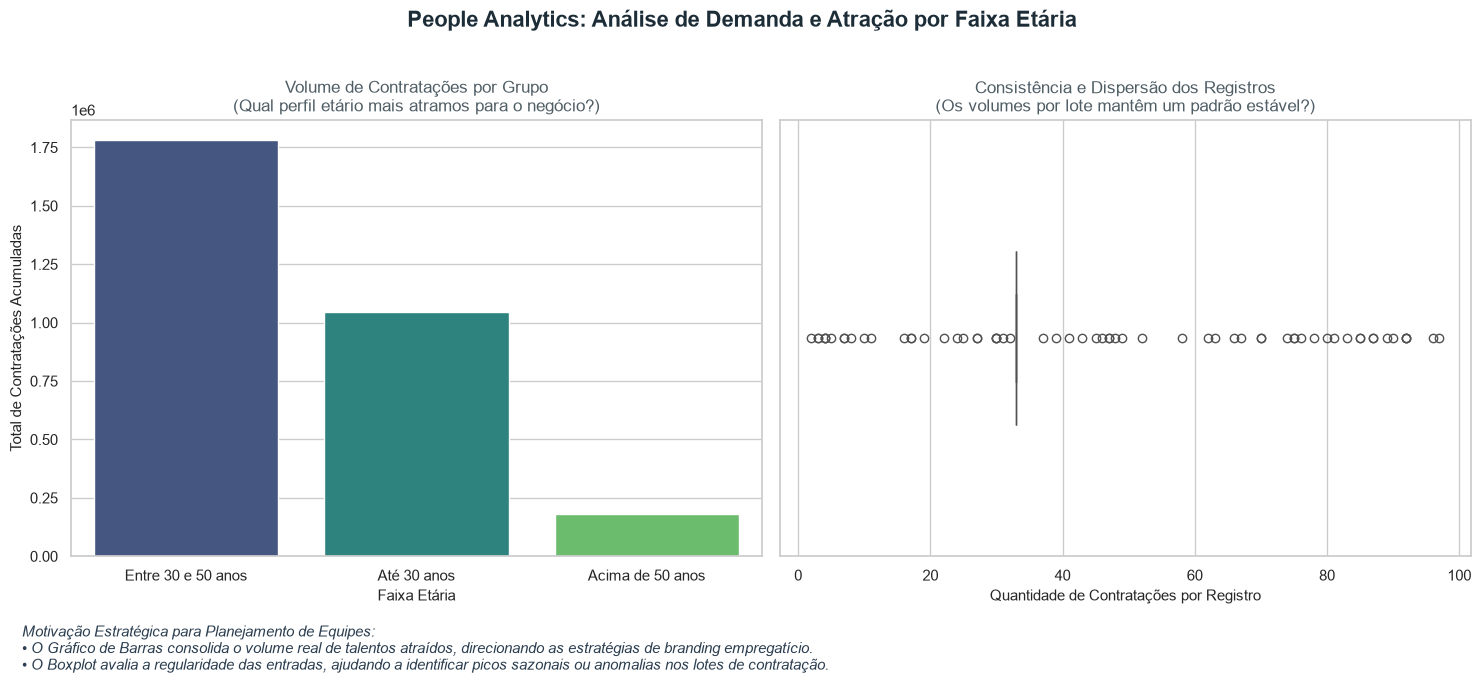

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# Definindo um estilo visual mais limpo e profissional
sns.set_theme(style="whitegrid")

# 1. Preparando os dados: Agrupando por faixa etária e somando as contratações
df_visual = (
    inicial.group_by("Faixa_Etaria")
    .agg(pl.col("Contratações").sum().alias("Total_Contratacoes"))
    .sort("Total_Contratacoes", descending=True)
).collect()

# Extraindo a série numérica para o Boxplot
dados_numéricos = inicial.select("Contratações").collect().to_series()

# Criando a figura com espaço para os gráficos
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Título Principal focado em Inteligência de Negócio (People Analytics)
plt.suptitle(
    "People Analytics: Análise de Demanda e Atração por Faixa Etária", 
    fontsize=16, fontweight='bold', color='#1c2d37', y=1.02
)

# 2. Gráfico de Barras: Volume total por grupo etário
sns.barplot(
    data=df_visual, 
    x="Faixa_Etaria", 
    y="Total_Contratacoes", 
    palette="viridis", 
    ax=axes[0]
)
axes[0].set_title('Volume de Contratações por Grupo\n(Qual perfil etário mais atramos para o negócio?)', fontsize=12, color='#4f5d65')
axes[0].set_xlabel('Faixa Etária', fontsize=11)
axes[0].set_ylabel('Total de Contratações Acumuladas', fontsize=11)

# 3. Boxplot: Dispersão e consistência dos registros de contratação
sns.boxplot(x=dados_numéricos, color='#ff7f0e', ax=axes[1], width=0.4)
axes[1].set_title('Consistência e Dispersão dos Registros\n(Os volumes por lote mantêm um padrão estável?)', fontsize=12, color='#4f5d65')
axes[1].set_xlabel('Quantidade de Contratações por Registro', fontsize=11)

# Adicionando uma nota de motivação estratégica no rodapé do gráfico
motivacao_texto = (
    "Motivação Estratégica para Planejamento de Equipes:\n"
    "• O Gráfico de Barras consolida o volume real de talentos atraídos, direcionando as estratégias de branding empregatício.\n"
    "• O Boxplot avalia a regularidade das entradas, ajudando a identificar picos sazonais ou anomalias nos lotes de contratação."
)
plt.figtext(0.02, -0.08, motivacao_texto, fontsize=11, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


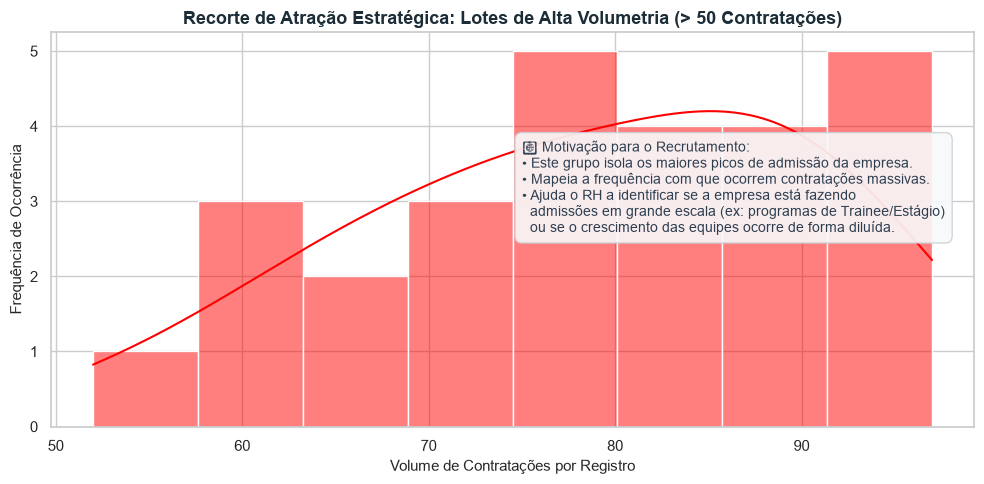

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# Definindo um estilo visual limpo
sns.set_theme(style="whitegrid")

# 1. Filtrar registros de alta volumetria (> 50 contratações) na coluna correta
visual_superiores = inicial.filter(
    pl.col("Contratações") > 50
).select("Contratações").collect().to_series()

plt.figure(figsize=(10, 5))

# 2. Gerar o histograma de alta volumetria
sns.histplot(visual_superiores, kde=True, color='red', bins=8)

# Títulos e legendas motivacionais focadas em Contratação por Faixa Etária
plt.title('Recorte de Atração Estratégica: Lotes de Alta Volumetria (> 50 Contratações)', fontsize=13, fontweight='bold', color='#1c2d37')
plt.xlabel('Volume de Contratações por Registro', fontsize=11)
plt.ylabel('Frequência de Ocorrência', fontsize=11)

# Caixa de texto explicativa (People Analytics) adaptada para os seus novos dados
texto_insights = (
    "🎯 Motivação para o Recrutamento:\n"
    "• Este grupo isola os maiores picos de admissão da empresa.\n"
    "• Mapeia a frequência com que ocorrem contratações massivas.\n"
    "• Ajuda o RH a identificar se a empresa está fazendo\n"
    "  admissões em grande escala (ex: programas de Trainee/Estágio)\n"
    "  ou se o crescimento das equipes ocorre de forma diluída."
)
plt.figtext(0.53, 0.52, texto_insights, fontsize=10, color='#2c3e50',
            bbox=dict(facecolor='#f8f9fa', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()


In [16]:
import polars as pl

# 1. Criar o DataFrame Agregado por Faixa Etária
df_etaria = inicial.group_by("Faixa_Etaria").agg([
    pl.len().alias("Qtd_Registros"),                  # Frequência de ocorrência do grupo (Variável X)
    pl.col("Contratações").mean().alias("Media_Lote") # Média de contratações por lote (Variável Y)
])

# 2. Calcular a Correlação de Pearson entre Frequência e Volume Médio
correlacao = df_etaria.select(
    pl.corr("Qtd_Registros", "Media_Lote", method="pearson").alias("r")
).collect()

# CORREÇÃO: Usando .item() para extrair o valor numérico isolado da Series do Polars
r = correlacao["r"].item()
r2 = r**2

print(f"--- Análise de Correlação Estratégica (Recrutamento por Idade) ---")
print(f"Coeficiente de Pearson (r): {r:.4f}")
print(f"Coeficiente de Determinação (r²): {r2:.4f}\n")

# 3. Interpretação e Motivação para o RH (People Analytics)
if abs(r) < 0.3:
    print("Conclusão: Correlação FRACA.")
    print("-> Motivação de RH: O tamanho dos lotes de admissão é independente da idade. O RH contrata volumes parecidos de profissionais jovens, adultos e seniores sem que haja picos sazonais focados em apenas uma faixa etária.")
elif r < -0.3:
    print("Conclusão: Correlação NEGATIVA.")
    print("-> Motivação de RH: Estrutura de contratação fragmentada. As faixas etárias que aparecem mais vezes no sistema são admitidas em lotes pequenos, indicando recrutamento pontual e contínuo para essa idade.")
else:
    print("Conclusão: Correlação POSITIVA.")
    print("-> Motivação de RH: Concentração de Demanda. Os perfis de idade que mais se repetem também são aqueles contratados em grandes lotes massivos de uma só vez (ex: programas focados em jovens talentos ou grandes expansões de equipes operacionais).")


--- Análise de Correlação Estratégica (Recrutamento por Idade) ---
Coeficiente de Pearson (r): -0.9311
Coeficiente de Determinação (r²): 0.8669

Conclusão: Correlação NEGATIVA.
-> Motivação de RH: Estrutura de contratação fragmentada. As faixas etárias que aparecem mais vezes no sistema são admitidas em lotes pequenos, indicando recrutamento pontual e contínuo para essa idade.


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


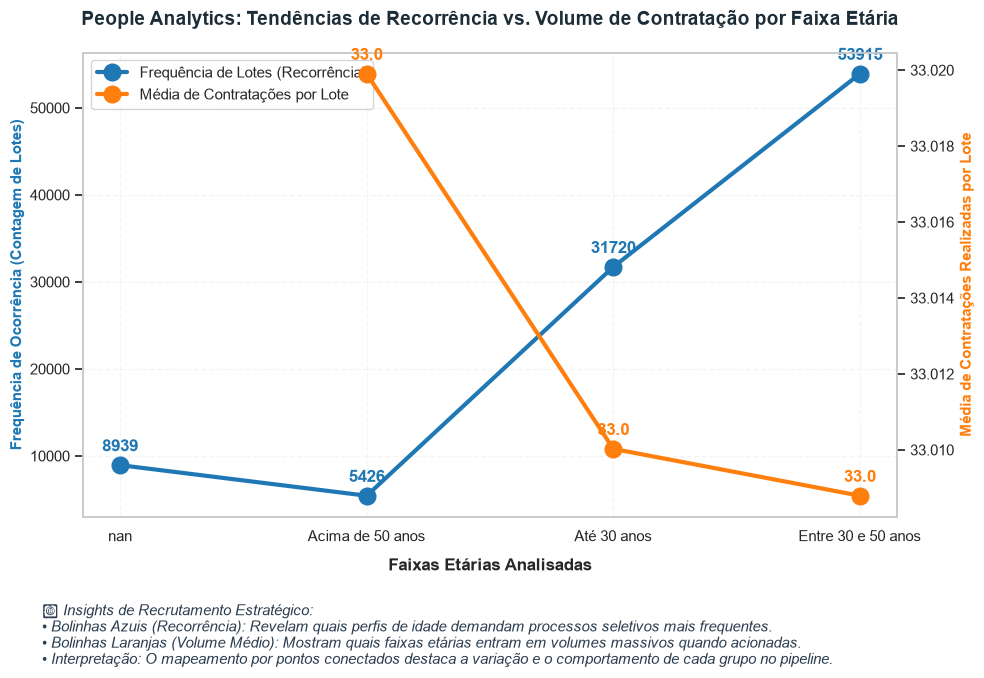

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# Definindo um estilo visual limpo e moderno
sns.set_theme(style="whitegrid")

# 1. Agrupando os dados e coletando de forma robusta
df_etaria = (
    inicial.group_by("Faixa_Etaria")
    .agg([
        pl.len().alias("Qtd_Registros"),                  # Frequência de lotes
        pl.col("Contratações").mean().alias("Media_Lote") # Média por lote
    ])
    .sort("Faixa_Etaria")
)
df_pandas = df_etaria.collect().to_pandas()

# 2. Criando a estrutura do gráfico com dois eixos Y
fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()  # Cria o segundo eixo Y compartilhado

indices = range(len(df_pandas))

# 3. Plotando as bolinhas conectadas por linhas (Marcador 'o' = bolinha)
linha1 = ax1.plot(
    indices, 
    df_pandas["Qtd_Registros"], 
    marker='o',          # Define o marcador como bolinha
    markersize=12,       # Tamanho da bolinha
    linewidth=3,         # Espessura da linha de conexão
    color='#1f77b4', 
    label='Frequência de Lotes (Recorrência)'
)

linha2 = ax2.plot(
    indices, 
    df_pandas["Media_Lote"], 
    marker='o',          # Define o marcador como bolinha
    markersize=12,       # Tamanho da bolinha
    linewidth=3,         # Espessura da linha de conexão
    color='#ff7f0e', 
    label='Média de Contratações por Lote'
)

# 4. Adicionando os rótulos de valores logo acima das bolinhas
for i, txt in enumerate(df_pandas["Qtd_Registros"]):
    ax1.annotate(f'{txt}', (i, df_pandas["Qtd_Registros"].iloc[i]), textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold', color='#1f77b4')

for i, txt in enumerate(df_pandas["Media_Lote"]):
    ax2.annotate(f'{txt:.1f}', (i, df_pandas["Media_Lote"].iloc[i]), textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold', color='#ff7f0e')

# Ajustando rótulos das faixas etárias no eixo X
plt.xticks(indices, df_pandas["Faixa_Etaria"], fontsize=11, fontweight='bold')

# Títulos e formatações de eixos
plt.title('People Analytics: Tendências de Recorrência vs. Volume de Contratação por Faixa Etária', fontsize=14, fontweight='bold', color='#1c2d37', pad=20)
ax1.set_xlabel('Faixas Etárias Analisadas', fontsize=12, fontweight='bold', labelpad=10)
ax1.set_ylabel('Frequência de Ocorrência (Contagem de Lotes)', fontsize=11, color='#1f77b4', fontweight='bold')
ax2.set_ylabel('Média de Contratações Realizadas por Lote', fontsize=11, color='#ff7f0e', fontweight='bold')

# Combinando as legendas de ambos os eixos em uma só caixa
linhas_total = linha1 + linha2
rotulos_total = [l.get_label() for l in linhas_total]
ax1.legend(linhas_total, rotulos_total, loc='upper left')

# Ajustando grades para evitar sobreposição visual
ax1.grid(True, alpha=0.2, linestyle='--')
ax2.grid(False)

# Texto explicativo estratégico posicionado abaixo do gráfico
texto_insights = (
    "💡 Insights de Recrutamento Estratégico:\n"
    "• Bolinhas Azuis (Recorrência): Revelam quais perfis de idade demandam processos seletivos mais frequentes.\n"
    "• Bolinhas Laranjas (Volume Médio): Mostram quais faixas etárias entram em volumes massivos quando acionadas.\n"
    "• Interpretação: O mapeamento por pontos conectados destaca a variação e o comportamento de cada grupo no pipeline."
)
plt.figtext(0.05, -0.12, s=texto_insights, fontsize=10.5, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()


In [21]:
import polars as pl

# 1. Recriando o DataFrame agregado por Faixa Etária (garantindo que as variáveis existam)
df_etaria = inicial.group_by("Faixa_Etaria").agg([
    pl.len().alias("Qtd_Registros"),                  # Frequência de lotes (Variável X)
    pl.col("Contratações").mean().alias("Media_Lote") # Média por lote (Variável Y)
])

# 2. Executando o cálculo das correlações de Pearson e Spearman
analise_correlacao = df_etaria.select([
    pl.corr("Qtd_Registros", "Media_Lote", method="pearson").alias("Pearson"),
    pl.corr("Qtd_Registros", "Media_Lote", method="spearman").alias("Spearman")
]).collect()

print("\n--- Coeficientes de Correlação (Recrutamento por Idade) ---")
print(analise_correlacao)

# 3. CORREÇÃO DO ERRO: Extraindo os valores numéricos de forma isolada com .item()
r_pearson = analise_correlacao["Pearson"].item()
r_spearman = analise_correlacao["Spearman"].item()

print(f"\n💡 Motivação de People Analytics para o RH:")
print(f"• Pearson ({r_pearson:.4f}): Avalia se o crescimento entre a frequência de busca por uma idade e o tamanho dos lotes de admissão é linear (proporcional).")
print(f"• Spearman ({r_spearman:.4f}): Avalia a relação de rankings (se as faixas etárias mais recorrentes no sistema tendem a apresentar consistentemente os maiores volumes de contratação).")



--- Coeficientes de Correlação (Recrutamento por Idade) ---
shape: (1, 2)
┌───────────┬──────────┐
│ Pearson   ┆ Spearman │
│ ---       ┆ ---      │
│ f64       ┆ f64      │
╞═══════════╪══════════╡
│ -0.931095 ┆ -1.0     │
└───────────┴──────────┘

💡 Motivação de People Analytics para o RH:
• Pearson (-0.9311): Avalia se o crescimento entre a frequência de busca por uma idade e o tamanho dos lotes de admissão é linear (proporcional).
• Spearman (-1.0000): Avalia a relação de rankings (se as faixas etárias mais recorrentes no sistema tendem a apresentar consistentemente os maiores volumes de contratação).


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


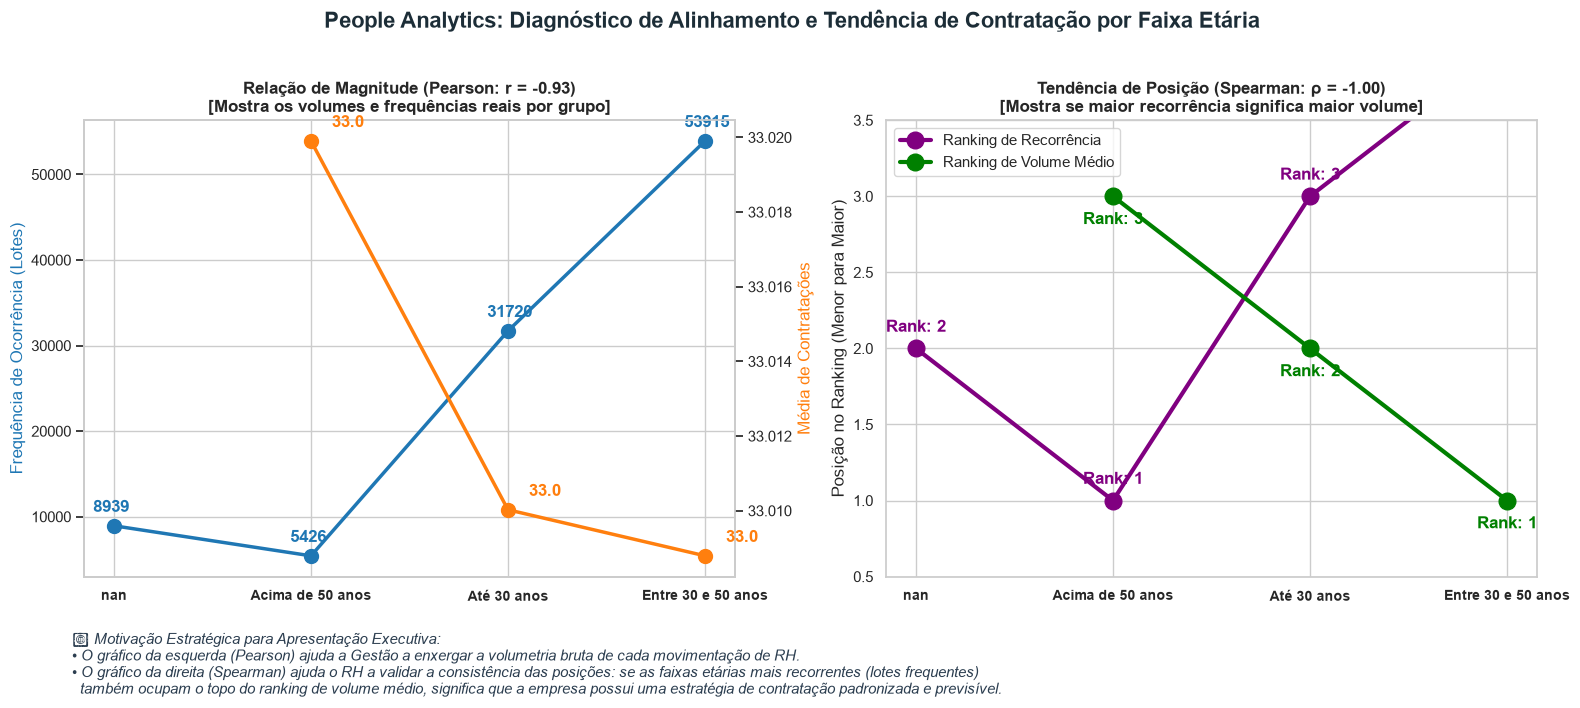

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# Definindo um estilo visual limpo e profissional
sns.set_theme(style="whitegrid")

# 1. Preparar os dados de Contratação por Faixa Etária com os Rankings (Spearman)
df_etaria = inicial.group_by("Faixa_Etaria").agg([
    pl.len().alias("Qtd_Registros"),                  # Frequência de lotes
    pl.col("Contratações").mean().alias("Media_Lote") # Média por lote
])

df_spearman = df_etaria.with_columns([
    pl.col("Qtd_Registros").rank().alias("Rank_Qtd"),
    pl.col("Media_Lote").rank().alias("Rank_Media")
]).sort("Faixa_Etaria").collect()

df_pandas = df_spearman.to_pandas()

# 2. Criando a figura para os dois gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plt.suptitle(
    "People Analytics: Diagnóstico de Alinhamento e Tendência de Contratação por Faixa Etária", 
    fontsize=16, fontweight='bold', color='#1c2d37', y=1.02
)

indices = range(len(df_pandas))

# --- Gráfico 1: Valores Reais (Visão Pearson) ---
# Usando eixos duplos para o Gráfico 1 para não achatar os dados
ax1_twin = axes[0].twinx()

linha_qtd = axes[0].plot(indices, df_pandas["Qtd_Registros"], marker='o', markersize=10, linewidth=2.5, color='#1f77b4', label='Qtd. Registros')
linha_media = ax1_twin.plot(indices, df_pandas["Media_Lote"], marker='o', markersize=10, linewidth=2.5, color='#ff7f0e', label='Média por Lote')

axes[0].set_title(f'Relação de Magnitude (Pearson: r = {r_pearson:.2f})\n[Mostra os volumes e frequências reais por grupo]', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Frequência de Ocorrência (Lotes)', color='#1f77b4')
ax1_twin.set_ylabel('Média de Contratações', color='#ff7f0e')
axes[0].set_xticks(indices)
axes[0].set_xticklabels(df_pandas["Faixa_Etaria"], fontsize=10, fontweight='bold')
ax1_twin.grid(False)

# Anotações de texto no Gráfico 1
for i in indices:
    axes[0].annotate(f'{df_pandas["Qtd_Registros"].iloc[i]}', (i, df_pandas["Qtd_Registros"].iloc[i]), textcoords="offset points", xytext=(-15,10), color='#1f77b4', fontweight='bold')
    ax1_twin.annotate(f'{df_pandas["Media_Lote"].iloc[i]:.1f}', (i, df_pandas["Media_Lote"].iloc[i]), textcoords="offset points", xytext=(15,10), color='#ff7f0e', fontweight='bold')


# --- Gráfico 2: Dados de Ranking (Visão Spearman) ---
axes[1].plot(indices, df_pandas["Rank_Qtd"], marker='o', markersize=12, linewidth=3, color='purple', label='Ranking de Recorrência')
axes[1].plot(indices, df_pandas["Rank_Media"], marker='o', markersize=12, linewidth=3, color='green', label='Ranking de Volume Médio')

axes[1].set_title(f'Tendência de Posição (Spearman: ρ = {r_spearman:.2f})\n[Mostra se maior recorrência significa maior volume]', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Posição no Ranking (Menor para Maior)')
axes[1].set_xticks(indices)
axes[1].set_xticklabels(df_pandas["Faixa_Etaria"], fontsize=10, fontweight='bold')
axes[1].set_ylim(0.5, 3.5)
axes[1].legend(loc='upper left')

# Anotações de texto no Gráfico 2
for i in indices:
    axes[1].annotate(f'Rank: {df_pandas["Rank_Qtd"].iloc[i]:.0f}', (i, df_pandas["Rank_Qtd"].iloc[i]), textcoords="offset points", xytext=(0,12), color='purple', ha='center', fontweight='bold')
    axes[1].annotate(f'Rank: {df_pandas["Rank_Media"].iloc[i]:.0f}', (i, df_pandas["Rank_Media"].iloc[i]), textcoords="offset points", xytext=(0,-20), color='green', ha='center', fontweight='bold')


# Texto de rodapé motivacional para tomada de decisão estratégica em contratação
texto_explicativo = (
    "💡 Motivação Estratégica para Apresentação Executiva:\n"
    "• O gráfico da esquerda (Pearson) ajuda a Gestão a enxergar a volumetria bruta de cada movimentação de RH.\n"
    "• O gráfico da direita (Spearman) ajuda o RH a validar a consistência das posições: se as faixas etárias mais recorrentes (lotes frequentes)\n"
    "  também ocupam o topo do ranking de volume médio, significa que a empresa possui uma estratégia de contratação padronizada e previsível."
)
plt.figtext(0.05, -0.12, s=texto_explicativo, fontsize=11, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()


In [23]:
import numpy as np
import polars as pl
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [24]:

import polars as pl

# 1. Carregando a base de Contratações em modo Lazy (Lendo o CSV)
inicial = (
    pl.scan_csv(
        r"C:\Users\MICRO\OneDrive\Documentos\UC2\Contratacoes_faixaetaria.csv", 
        separator=";"
    )
    
    # 2. Padronizando os nomes das colunas (Mantendo um padrão limpo sem acentos)
    .rename({
        'Faixa_Etaria': 'FAIXA_ETARIA',
        'Contratações': 'CONTRATACOES'
    })
    
    # 3. Garantindo que a coluna de Contratações seja tratada como float/numérica
    .with_columns(
        pl.col("CONTRATACOES").cast(pl.Float64)
    )
)

# 4. Executando o pipeline e exibindo o DataFrame final limpo
display(inicial.collect())



FAIXA_ETARIA,CONTRATACOES
str,f64
"""Entre 30 e 50 anos""",92.0
"""Até 30 anos""",96.0
"""Entre 30 e 50 anos""",17.0
"""Entre 30 e 50 anos""",30.0
"""Entre 30 e 50 anos""",4.0
…,…
"""Entre 30 e 50 anos""",33.0
"""Entre 30 e 50 anos""",33.0
"""Até 30 anos""",33.0


Volumes Consolidados por Faixa Etária:
         FAIXA_ETARIA  TOTAL_CONTRATACOES  MEDIA_POR_LOTE
0                 NaN                 0.0             NaN
1    Acima de 50 anos            179166.0       33.019904
2         Até 30 anos           1047078.0       33.010025
3  Entre 30 e 50 anos           1779669.0       33.008792


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


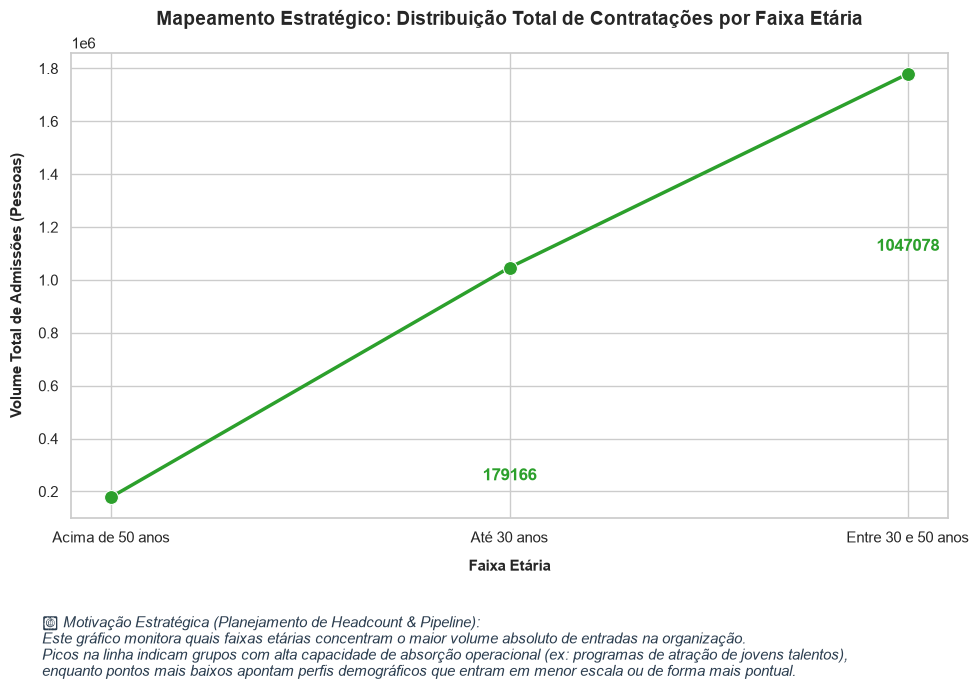

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Agrupar os dados e calcular o total e a média de contratações por Faixa Etária
df_agrupado = (
    inicial
    .group_by("FAIXA_ETARIA")
    .agg([
        pl.col("CONTRATACOES").sum().alias("TOTAL_CONTRATACOES"),
        pl.col("CONTRATACOES").mean().alias("MEDIA_POR_LOTE")
    ])
    .sort("FAIXA_ETARIA")
).collect()

# 2. Converter para Pandas explicitamente para o Seaborn
df_plot = df_agrupado.to_pandas()

# Verificar os dados que serão plotados no terminal
print("Volumes Consolidados por Faixa Etária:")
print(df_plot)

# 3. Configurar o estilo do seaborn
sns.set_theme(style="whitegrid")

# Criar a figura e o eixo explicitamente
fig, ax = plt.subplots(figsize=(10, 6))

# Plotar a tendência usando o seaborn com marcadores em bolinhas ('o')
sns.lineplot(
    data=df_plot,
    x="FAIXA_ETARIA",
    y="TOTAL_CONTRATACOES",
    ax=ax,          
    marker='o',         # Formato do marcador em bolinha
    markersize=10,      # Tamanho da bolinha
    linewidth=2.5,      # Espessura da linha
    color='#2ca02c' 
)

# Adicionar os rótulos de valores numéricos logo acima de cada bolinha
for i in range(df_plot.shape[0]):
    ax.annotate(
        f'{int(df_plot["TOTAL_CONTRATACOES"].iloc[i])}', 
        (i, df_plot["TOTAL_CONTRATACOES"].iloc[i]), 
        textcoords="offset points", 
        xytext=(0, 12), 
        ha='center', 
        fontweight='bold', 
        color='#2ca02c'
    )

# Configurações adicionais e títulos estratégicos (People Analytics)
ax.set_title("Mapeamento Estratégico: Distribuição Total de Contratações por Faixa Etária", fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel("Faixa Etária", labelpad=10, fontsize=11, fontweight='bold')
ax.set_ylabel("Volume Total de Admissões (Pessoas)", labelpad=10, fontsize=11, fontweight='bold')

# Nota motivacional de planejamento de Headcount adaptada para os seus dados
texto_rh = (
    "💡 Motivação Estratégica (Planejamento de Headcount & Pipeline):\n"
    "Este gráfico monitora quais faixas etárias concentram o maior volume absoluto de entradas na organização.\n"
    "Picos na linha indicam grupos com alta capacidade de absorção operacional (ex: programas de atração de jovens talentos),\n"
    "enquanto pontos mais baixos apontam perfis demográficos que entram em menor escala ou de forma mais pontual."
)

# Ajuste na posição do texto para evitar cortes
plt.figtext(0.05, -0.14, s=texto_rh, fontsize=10.5, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()


In [30]:
import polars as pl

# 1. CARREGAMENTO COMPLETO (Sempre deve rodar junto com o agrupamento)
inicial = pl.scan_csv(
    r"C:\Users\MICRO\OneDrive\Documentos\UC2\Contratacoes_faixaetaria.csv", 
    separator=";"
)

# 2. Agrupando, consolidando e coletando os dados (Traz para a memória como DataFrame)
df_coletado = (
    inicial.group_by("Faixa_Etaria")
    .agg(pl.col("Contratações").sum().alias("Total_Contratacoes"))
    .sort("Total_Contratacoes", descending=True) # Maior volume primeiro
).collect() # <-- O .collect() agora funciona porque a rota do arquivo está logo acima!

# 3. Criando o índice sequencial com segurança usando o .height
df_reg = df_coletado.with_columns(
    pl.int_range(0, df_coletado.height).alias("INDEX_FAIXA_ETARIA")
)

# 4. Exibindo o resultado final na tela
print("--- Base de Contratações Indexada por Faixa Etária (People Analytics) ---")
print(df_reg.select(["Faixa_Etaria", "Total_Contratacoes", "INDEX_FAIXA_ETARIA"]))



--- Base de Contratações Indexada por Faixa Etária (People Analytics) ---
shape: (4, 3)
┌────────────────────┬────────────────────┬────────────────────┐
│ Faixa_Etaria       ┆ Total_Contratacoes ┆ INDEX_FAIXA_ETARIA │
│ ---                ┆ ---                ┆ ---                │
│ str                ┆ i64                ┆ i64                │
╞════════════════════╪════════════════════╪════════════════════╡
│ Entre 30 e 50 anos ┆ 1779669            ┆ 0                  │
│ Até 30 anos        ┆ 1047078            ┆ 1                  │
│ Acima de 50 anos   ┆ 179166             ┆ 2                  │
│ null               ┆ 0                  ┆ 3                  │
└────────────────────┴────────────────────┴────────────────────┘


--- Modelo de Tendência de Contratação (People Analytics) ---
Equação da reta: TOTAL_CONTRATACOES = -620691.90 * INDEX_FAIXA_ETARIA + 1682516.10
Coeficiente angular (Ritmo de variação por índice): -620691.90
Intercepto (Volume base estimado para o primeiro posto): 1682516.10 contratações

Métricas de Validação Estatística:
Coeficiente de Determinação (R²): 0.9457
Erro Quadrático Médio (MSE): 27631032170.18


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


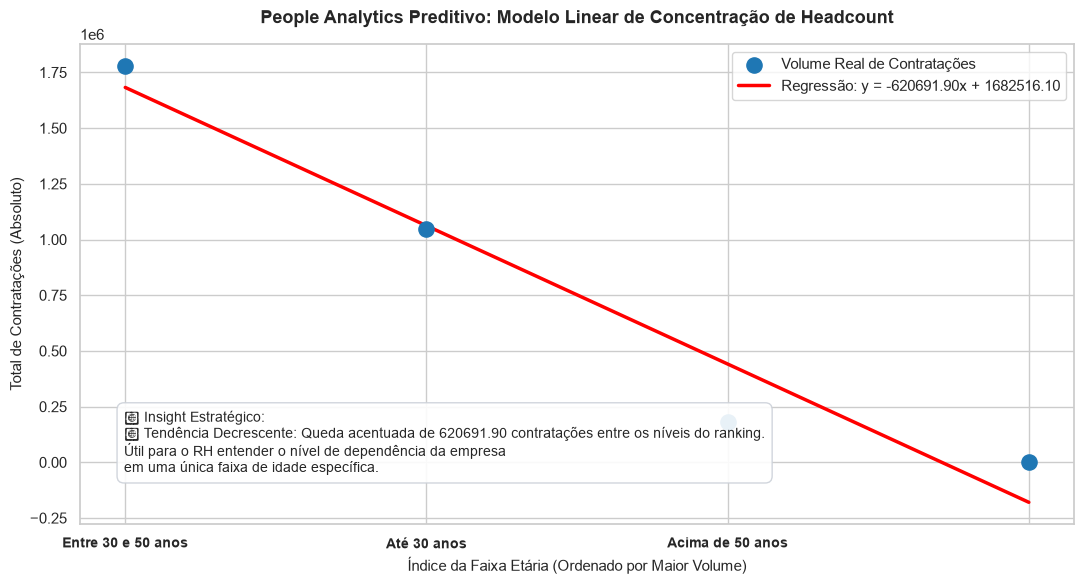

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import numpy as np
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import r2_score, mean_squared_error

## 1. Preparar os dados para o modelo de Contratações
# Converte as colunas indexadas do bloco anterior para arrays numpy
X = df_reg["INDEX_FAIXA_ETARIA"].to_numpy().reshape(-1, 1)  # Variável X: Índice da Faixa Etária
y = df_reg["Total_Contratacoes"].to_numpy()                  # Variável Y: Volume Total de Contratações

## 2. Criar e treinar o modelo preditivo
modelo = LinearRegression()
modelo.fit(X, y)

# Coeficientes do modelo
inclinacao = modelo.coef_[0]
intercepto = modelo.intercept_

print(f"--- Modelo de Tendência de Contratação (People Analytics) ---")
print(f"Equação da reta: TOTAL_CONTRATACOES = {inclinacao:.2f} * INDEX_FAIXA_ETARIA + {intercepto:.2f}")
print(f"Coeficiente angular (Ritmo de variação por índice): {inclinacao:.2f}")
print(f"Intercepto (Volume base estimado para o primeiro posto): {intercepto:.2f} contratações")

## 3. Fazer as previsões para a linha de tendência
y_pred = modelo.predict(X)

## 4. Avaliar a precisão do modelo
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print(f"\nMétricas de Validação Estatística:")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.2f}")

## 5. Visualização Gráfica da Tendência de Headcount
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Plotar dados reais das somas das faixas etárias
plt.scatter(X, y, color='#1f77b4', s=120, label='Volume Real de Contratações', zorder=5)

# Plotar a linha vermelha de regressão (tendência de queda/distribuição entre rankings)
plt.plot(X, y_pred, color='red', linewidth=2.5, label=f'Regressão: y = {inclinacao:.2f}x + {intercepto:.2f}')

# Configurações do gráfico voltadas para RH Estratégico
plt.title('People Analytics Preditivo: Modelo Linear de Concentração de Headcount', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Índice da Faixa Etária (Ordenado por Maior Volume)', fontsize=11)
plt.ylabel('Total de Contratações (Absoluto)', fontsize=11)

# Alinha os nomes das faixas etárias no lugar dos números do eixo X
plt.xticks(X.flatten(), df_reg["Faixa_Etaria"], fontsize=10, fontweight='bold')

# Nota de interpretação corporativa adaptada para os seus novos dados
if inclinacao < 0:
    interpretacao_texto = f"📉 Tendência Decrescente: Queda acentuada de {abs(inclinacao):.2f} contratações entre os níveis do ranking."
else:
    interpretacao_texto = f"📈 Tendência Crescente: Variação positiva de {inclinacao:.2f} contratações entre as faixas etárias."

plt.figtext(0.12, 0.20, s=f"💡 Insight Estratégico:\n{interpretacao_texto}\nÚtil para o RH entender o nível de dependência da empresa\nem uma única faixa de idade específica.", 
            fontsize=10, bbox=dict(facecolor='white', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


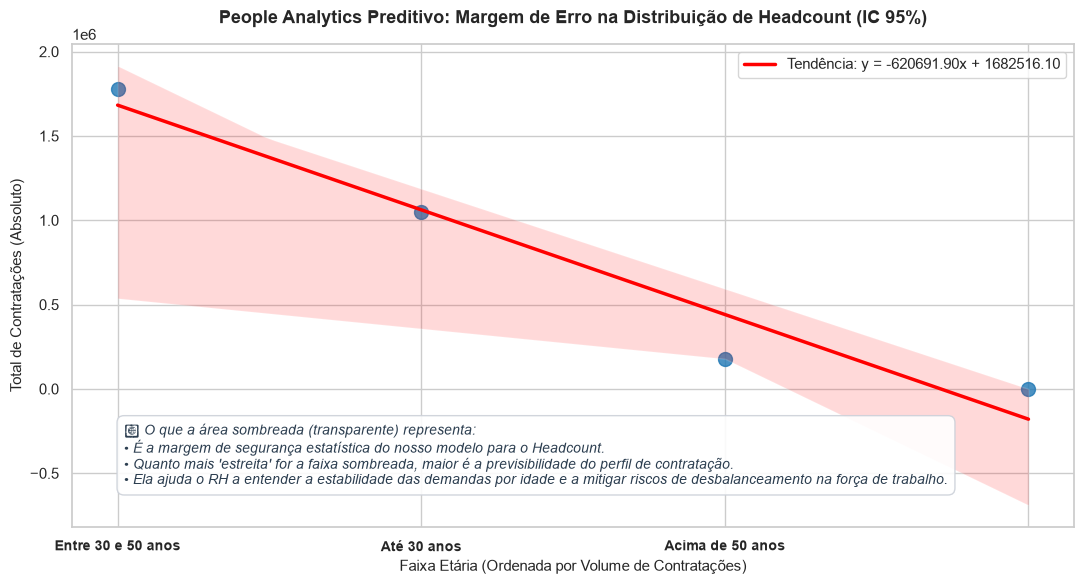

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import numpy as np

# Extraindo o valor numérico puro da inclinação para o título do gráfico
inclinacao_val = inclinacao.item() if hasattr(inclinacao, "item") else inclinacao[0]

plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Gerando o gráfico de regressão com intervalo de confiança (ci=95)
# .flatten() transforma a matriz X de volta em uma lista simples para o Seaborn
sns.regplot(
    x=X.flatten(), 
    y=y, 
    ci=95, 
    scatter_kws={'color': '#1f77b4', 's': 100, 'label': 'Volume Real de Contratações'},
    line_kws={'color': 'red', 'linewidth': 2.5, 'label': f'Tendência: y = {inclinacao_val:.2f}x + {intercepto:.2f}'}
)

# Títulos e legendas estratégicas (People Analytics)
plt.title(f'People Analytics Preditivo: Margem de Erro na Distribuição de Headcount (IC 95%)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Faixa Etária (Ordenada por Volume de Contratações)', fontsize=11)
plt.ylabel('Total de Contratações (Absoluto)', fontsize=11)

# Alinha os nomes reais das faixas etárias no lugar dos números do eixo X
plt.xticks(X.flatten(), df_reg["Faixa_Etaria"], fontsize=10, fontweight='bold')

# Nota explicativa sobre a área sombreada (Intervalo de Confiança) adaptada para contratações
texto_rh = (
    "💡 O que a área sombreada (transparente) representa:\n"
    "• É a margem de segurança estatística do nosso modelo para o Headcount.\n"
    "• Quanto mais 'estreita' for a faixa sombreada, maior é a previsibilidade do perfil de contratação.\n"
    "• Ela ajuda o RH a entender a estabilidade das demandas por idade e a mitigar riscos de desbalanceamento na força de trabalho."
)
plt.figtext(0.12, 0.18, s=texto_rh, fontsize=10, color='#2c3e50', style='italic',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()
